# Bayesian Analysis with Python - Part 2

## Introduction

This is an acccount of my adventures with trying (yet again) to get into Bayesian statistics.  I am working through a paper copy of __Bayesian Analysis with Python: A practical guide to probabilistic modeling (Edition 3)__
by Osvaldo Martin

We work through two models for data that has a few outlier values, and compare the models

## Implementation

### Imports

In [11]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm
import pytensor

### Data load

Load the data and visualizeit as a scatter plot

In [12]:
data_url = "data/chemical_shifts.csv"
observed = pd.read_csv(data_url)

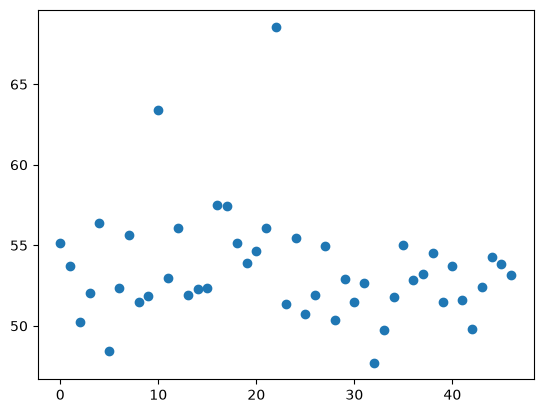

In [13]:
plt.plot(observed, "o")

### Modelling

First we configure PyTensor to __not__ expect compilation facilities to be available (conflicting libraries in my environment)

In [14]:
pytensor.config.cxx = ""

#### Fit a Normal

We decide to fit a Normal to the data: 

- we decalre the mean to be between 40 and 60 (and have no belief that any vale between 40 and 60 is more likely - a flat or uninformative Prior).
- we enforce the standard deviation (SD) to be greater than zero: for the density of SD,  we select a Half Normal with a standard deviation of 5

We run the model, to generate _idata_, the model results data-structure.

We get library clash warning which we ignore (running on Windows)

In [15]:
with pm.Model() as shift_model:
    mu = pm.Uniform("mu", lower=40, upper=60)
    sigma = pm.HalfNormal("sigma", sigma=5)
    Y = pm.Normal("Y", mu=mu, sigma=sigma, observed=observed)
    idata = pm.sample()

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, sigma]


Output()

We examine the model diagnostics to check all OK (it is)

In [16]:
problems = az.diagnose(idata)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


We ask for summary statistics

In [17]:
az.summary(idata, kind="stats", ci_kind="hdi")

,mean,sd,hdi89_lb,hdi89_ub
mu,54,0.51,53,54
sigma,3.5,0.38,2.9,4.1


We ask for a model diagram to check that the model we computed is what it should be (it is)

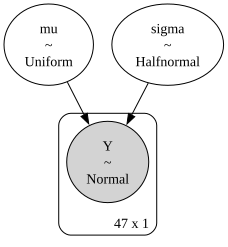

In [18]:
pm.model_to_graphviz(shift_model)

--------------

### Check model executiuon

Check the random  modelling diagnostic plots, to check modelling (appears ok)


az.plot_trace_dist(idata)

 Examine the posterior estimates of mean and standard deviation

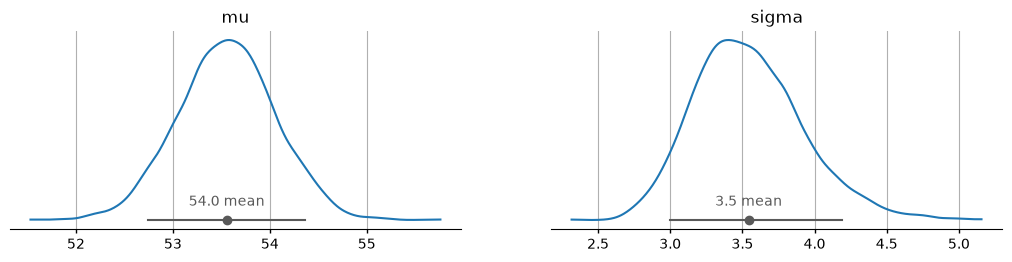

In [19]:
pc = az.plot_dist(idata)
pc.viz["figure"].item().get_axes()[0].grid(True, axis="both")
pc.viz["figure"].item().get_axes()[1].grid(True, axis="both")

Examine the correlations between mean and standard deviation

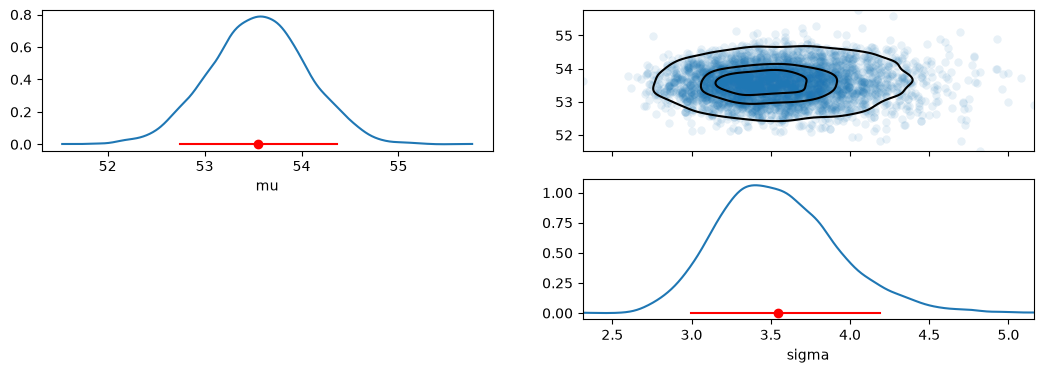

In [20]:
az.plot_pair(
    idata,
    var_names=["mu", "sigma"],
    marginal=True,
    marginal_kind="kde",
    visuals={
        "contour": True,
        "scatter": {"alpha": 0.1},
        "credible_interval": {"color": "red"},
        "point_estimate": {"color": "red"},
    },
    triangle="upper",
)

Extend the model data structures to examine more aspects

In [21]:
with shift_model:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True)
# end with

Sampling: [Y]


Output()

Compare the predictions of data values probability density with the actual values (without a grid, and then with a grid)

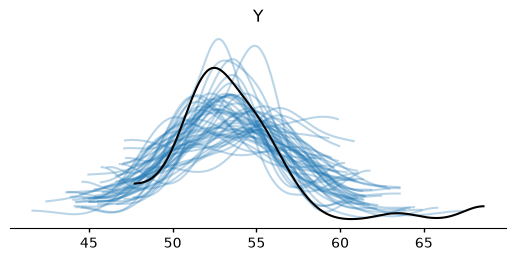

In [22]:
with shift_model:
    pc = az.plot_ppc_dist(
        idata,
        kind="kde",
    )
# end with

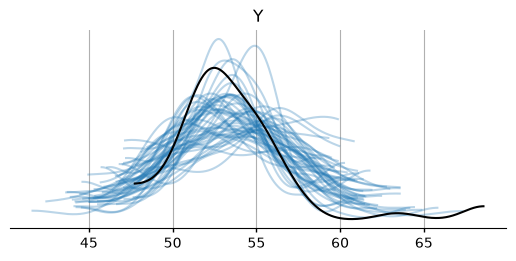

In [23]:
pc.viz["figure"].item().get_axes()[0].grid(True, axis="both")
pc.viz["figure"].item()

----------------------------

## Using Fat Tail distribution

Considering the plots above,  the suggestion is that the outlier values may be leading to misalignment of the predicted peaks in the KDE, as compatred to the actuals.

One solution is to use a Student T distribution (which can be "Fat Tailed", depending on a "degrees of freedom" parameter ($\nu$).  Our model replaces the Normal distribution with a Students T, and the nu ($\nu$) value is drawn from a Exponential, with a width of about 30

In [24]:
with pm.Model() as shift_model_t:
    mu = pm.Uniform("mu", lower=40, upper=60)
    sigma = pm.HalfNormal("sigma", sigma=5)
    nu = pm.Exponential("nu", 1 / 30)
    Y = pm.StudentT("Y", mu=mu, sigma=sigma, nu=nu, observed=observed)
    idata = pm.sample()

# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu, sigma, nu]


Output()

#### Check model run
We check diagnostics (seems OK)

In [25]:
problems = az.diagnose(idata)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


Check the summary statistics - seems OK

In [26]:
az.summary(idata, kind="stats", ci_kind="hdi")

,mean,sd,hdi89_lb,hdi89_ub
mu,53,0.38,52,54
sigma,2.2,0.4,1.6,2.8
nu,4.6,3.5,1.3,7.4


Check thge model diagram (seem OK)

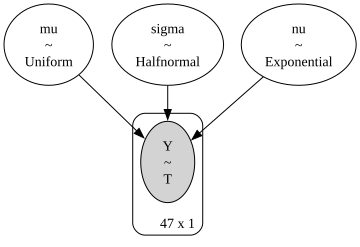

In [27]:
pm.model_to_graphviz(shift_model_t)

------------
#### Check model execution

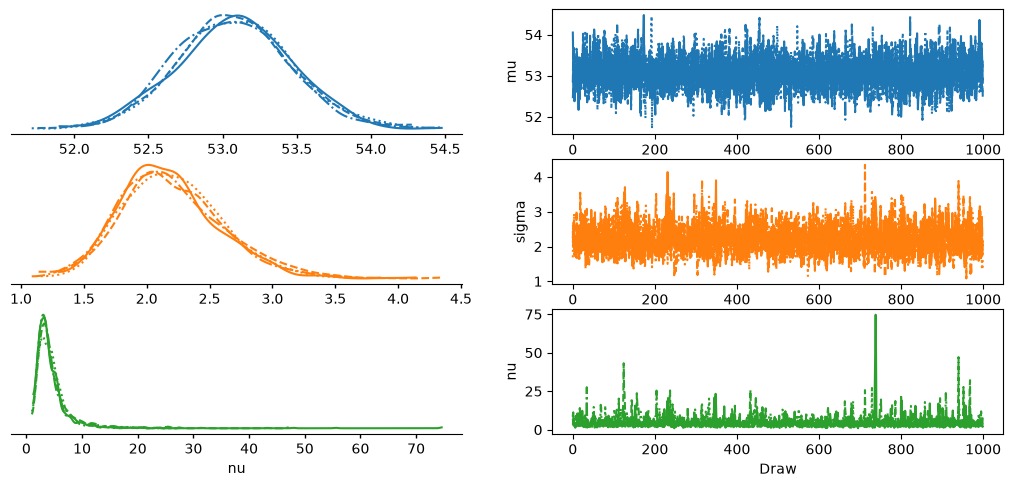

In [28]:
az.plot_trace_dist(idata)

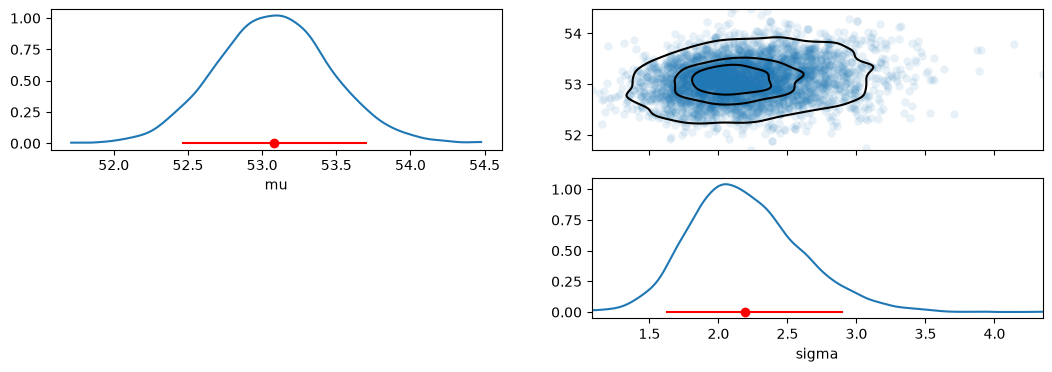

In [29]:
az.plot_pair(
    idata,
    var_names=["mu", "sigma"],
    marginal=True,
    marginal_kind="kde",
    visuals={
        "contour": True,
        "scatter": {"alpha": 0.1},
        "credible_interval": {"color": "red"},
        "point_estimate": {"color": "red"},
    },
    triangle="upper",
)

Extend model data structures to allow more plots to be generated

In [30]:
with shift_model_t:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True)
# end with

Sampling: [Y]


Output()

-------------

#### Examine density predictions

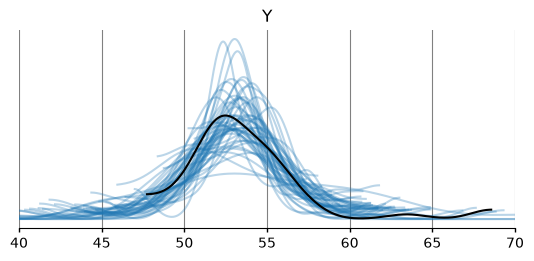

In [31]:
with shift_model_t:
    pc_t = az.plot_ppc_dist(
        idata,
        kind="kde",
    )
    pc_t.map(az.visuals.set_xlim, limits=(40, 70))
    pc_t.map(az.visuals.grid, axis="x", color="gray")
# end with

Compared to the original (Normal  model) predictions (see below), the Student T model appears to match the central peak better

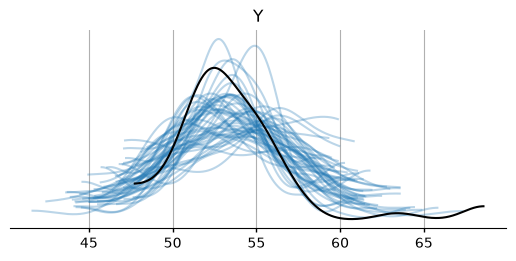

In [32]:
pc.viz["figure"].item()

------------------

## Conclusions

It was a salutory lesson in how Normal distributions are __not__ always the best to use, and how easy it was to move to a different model

-----------------------

## Reproducability

In [33]:
%load_ext watermark

In [34]:
%watermark

Last updated: 2026-09-22T14:33:11.291029+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [35]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1
pytensor  : 3.3.0

